# 03. Finding the cheapest plan

**Notebook version:** v1.0.0 (2026-10-20) &nbsp;|&nbsp; All numbers are illustrative, not from any real company or process.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## The search
We allow five levels of checking at each of three steps (none, 10%, 25%, 50%, all). That gives 5 x 5 x 5 = **125 possible plans**. We simulate each one and rank them by total cost.

In [2]:
from src.search import rank_plans, describe_plan
ranked = rank_plans(n_units=100_000, seed=0)
top = ranked.head(10).copy()
top["plan"] = top["plan"].map(describe_plan)
top[["plan", "total", "inspection", "slowdown", "scrap", "escaped"]].round(2)

,plan,total,inspection,slowdown,scrap,escaped
rank,,,,,,
1,Surface prep: none | Stack assembly: all | Fin...,9.55,3.91,1.96,2.83,0.86
2,Surface prep: 10% | Stack assembly: all | Fina...,9.79,4.11,2.05,2.78,0.85
3,Surface prep: none | Stack assembly: 50% | Fin...,9.94,2.95,1.48,3.56,1.95
4,Surface prep: 10% | Stack assembly: 50% | Fina...,10.10,3.15,1.58,3.49,1.88
5,Surface prep: none | Stack assembly: 25% | Fin...,10.13,2.48,1.24,3.93,2.48
6,Surface prep: 25% | Stack assembly: all | Fina...,10.15,4.40,2.20,2.70,0.84
7,Surface prep: none | Stack assembly: 10% | Fin...,10.19,2.19,1.10,4.14,2.76
8,Surface prep: 10% | Stack assembly: 25% | Fina...,10.25,2.68,1.34,3.85,2.39
9,Surface prep: 10% | Stack assembly: 10% | Fina...,10.30,2.39,1.19,4.05,2.66


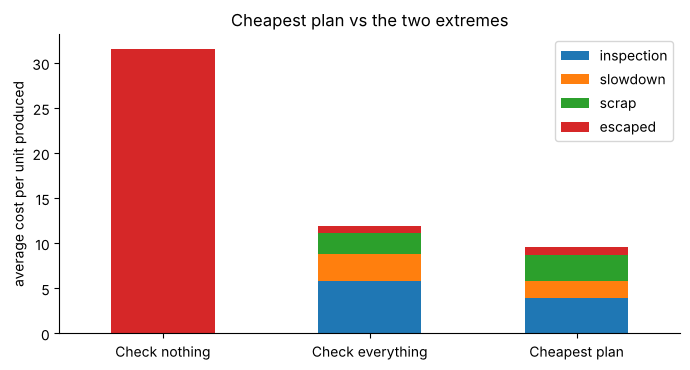

Cheapest plan: Surface prep: none | Stack assembly: all | Final integration: all
Saves 22.0 per unit vs checking nothing and 2.4 per unit vs checking everything.


In [3]:
none = ranked[ranked["plan"] == (0.0, 0.0, 0.0)].iloc[0]
everything = ranked[ranked["plan"] == (1.0, 1.0, 1.0)].iloc[0]
best = ranked.iloc[0]
cmp = pd.DataFrame({"Check nothing": none, "Check everything": everything, "Cheapest plan": best})
cmp = cmp.loc[["inspection", "slowdown", "scrap", "escaped"]].astype(float).T
ax = cmp.plot(kind="bar", stacked=True, figsize=(7, 3.8), rot=0)
ax.set_ylabel("average cost per unit produced")
ax.set_title("Cheapest plan vs the two extremes")
plt.tight_layout()
plt.savefig(ROOT / "docs" / "figures" / "cheapest_vs_extremes.png", dpi=150)
plt.show()
print("Cheapest plan:", describe_plan(best["plan"]))
print(f"Saves {none['total'] - best['total']:.1f} per unit vs checking nothing "
      f"and {everything['total'] - best['total']:.1f} per unit vs checking everything.")

**Reading this:** in this default example the cheapest plan skips checking after the first step (a defect created there can still be caught later at the same cost) and checks every unit after steps 2 and 3. Checking everywhere is not the cheapest. The point: the best answer is usually a targeted plan, not simply "check more" or "check less". Change the inputs in `src/cost_model.py` and the answer changes too.